# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Edwards, Kamal Sangameswaran, Jiaxian Wang


**Date:** 11/4/2026

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   8  18  85 156 228 137  93  10   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  13 183 254 254 254 254 254 254 210 147   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  16 179 254 254 254 254 254 254 254 254 251  97   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0 160 254 254 253 172  65  65 101 243 254 254 233  25   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0 148 140  47  46   0   0   0   0  84 247 254 25

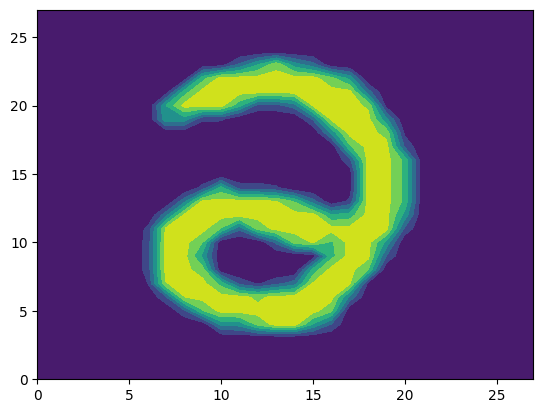

5 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  24  96 255 253 173  12   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  16 186 251 253 251 235  27   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  16 189 251 251 253 235  63   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  72 251 251 251 229  66   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  60 228 251 251 251  59   0   0   

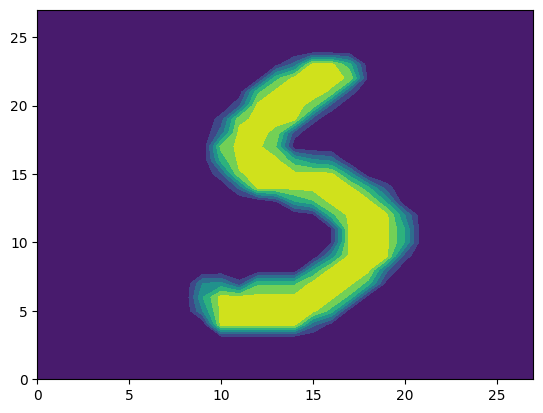

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  62 208 254 254 255 254 241 156  47   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 164 253 253 253 254 253 253 253 247  20   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  11 238 221 127 127 217 197 222 253 25

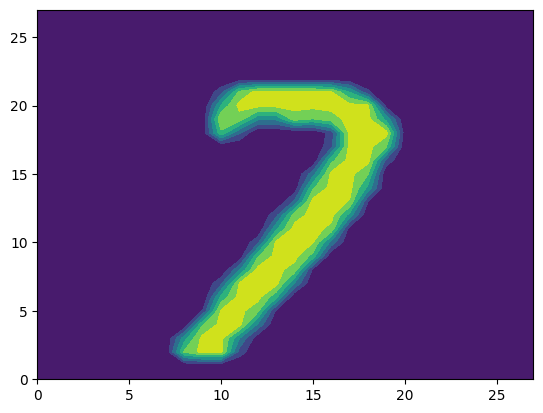

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  50   7   0   0   0   0   0   0   0   0   0  12 198 133   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  69 253  80   0   0   0   0   0   0   0   0   0  18 254 246   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 208 191   1   0   0   0   0   0   0   0   0   0  1

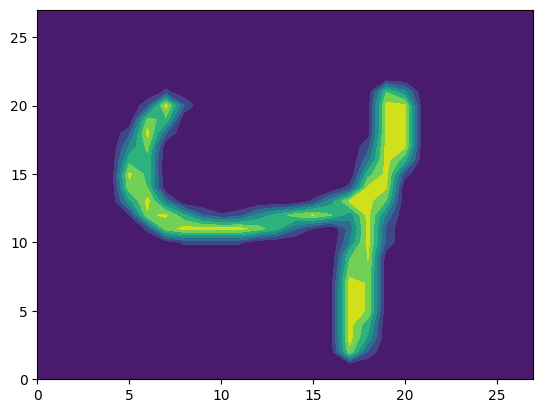

5 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   5   9  32 144 176 176   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   3  31 116 223 254 255 254 254 254   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  25 101 115 184 198 254 25

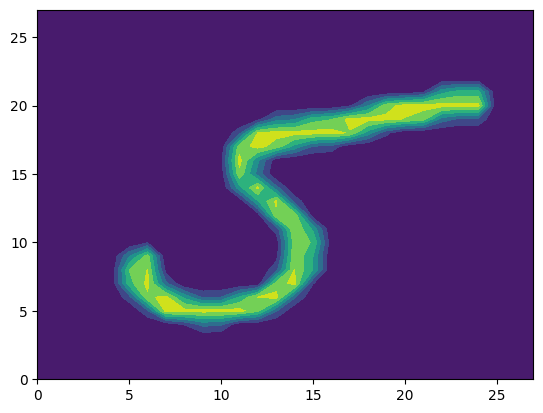

In [8]:
# Q1: Load and Visualize the Data
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the course data from the data folder or the current directory
try:
    with open('data/minst.pkl', 'rb') as f:
        data = pickle.load(f)
except FileNotFoundError:
    with open('minst.pkl', 'rb') as f:
        data = pickle.load(f)

X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# Display the labels, pixel values, and images for the first five test digits
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()


In [9]:
# Q2: Shapes of the Data
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"X_train[i] shape: {X_train.shape[1:]}")
print(f"X_test[i] shape: {X_test.shape[1:]}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

# each image is a 28 x 28 matrix of pixel values. The first dimension of
# X_train and X_test counts the images, and each label vector has one
# digit label for each image. All images in each array have the same shape.


X_train shape: (5000, 28, 28)
X_test shape: (1000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
y_train shape: (5000,)
y_test shape: (1000,)


In [10]:
# Q3: Reshaping Images into Feature Vectors
X_train_flat = np.array([img.reshape(784) for img in X_train])
X_test_flat = np.array([img.reshape(784) for img in X_test])

print(f"Reshaped Training Matrix: {X_train_flat.shape}")
print(f"Reshaped Testing Matrix: {X_test_flat.shape}")

# each 28 x 28 image becomes a vector of 784 pixel values.
# Each row represents one image, and each column represents one pixel.


Reshaped Training Matrix: (5000, 784)
Reshaped Testing Matrix: (1000, 784)


In [11]:
# Q4: Selecting the Number of Neighbors
# Use a validation split from the training data to compare k values
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_flat, y_train, test_size=0.2, random_state=42, stratify=y_train
)

best_k = 1
best_val_acc = 0
k_values = [1, 3, 5, 7, 9]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr, y_tr)
    val_preds = knn.predict(X_val)
    val_acc = accuracy_score(y_val, val_preds)
    print(f"k = {k} -> Validation Accuracy = {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_k = k

print(f"Best k among the values tested: {best_k}")

# k = 1 has the highest validation accuracy among the values tested
# on this split. The test set is reserved for the final evaluation.


k = 1 -> Validation Accuracy = 0.9290
k = 3 -> Validation Accuracy = 0.9250
k = 5 -> Validation Accuracy = 0.9190
k = 7 -> Validation Accuracy = 0.9240
k = 9 -> Validation Accuracy = 0.9250
Best k among the values tested: 1


In [12]:
# Q5: Test Accuracy and Confusion Matrix
opt_knn = KNeighborsClassifier(n_neighbors=best_k)
opt_knn.fit(X_train_flat, y_train)
y_pred = opt_knn.predict(X_test_flat)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy with k={best_k}: {test_accuracy*100:.2f}%")
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
print("\nConfusion Matrix (rows = actual digits, columns = predicted digits):")
print(cm)

report = classification_report(y_test, y_pred, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

f1_scores = {str(i): report[str(i)]['f1-score'] for i in range(10)}
best_digit = max(f1_scores, key=f1_scores.get)
worst_digit = min(f1_scores, key=f1_scores.get)
print(f"Best performing digit: {best_digit} (F1 = {f1_scores[best_digit]:.4f})")
print(f"Worst performing digit: {worst_digit} (F1 = {f1_scores[worst_digit]:.4f})")

# the classifier correctly predicts 93.30% of the test images.
# Most entries are on the diagonal of the confusion matrix, which means
# the predicted digit usually matches the actual digit. The best F1-score
# is for 7, while 8 has the lowest F1-score. Distinct strokes can make
# digits easier to identify, while variations in handwriting can make
# different digits look similar to a pixel-distance classifier like kNN.


Test Accuracy with k=1: 93.30%

Confusion Matrix (rows = actual digits, columns = predicted digits):
[[ 98   0   1   0   0   0   0   0   0   0]
 [  0 113   0   0   0   0   0   0   0   0]
 [  1   6  88   2   0   0   1   1   1   0]
 [  0   1   2  95   0   1   0   0   3   0]
 [  0   0   0   0  91   0   1   0   0   6]
 [  0   0   0   8   0  79   0   0   1   2]
 [  1   0   0   0   0   1  96   0   0   0]
 [  0   0   0   0   0   0   0 104   0   0]
 [  1   4   0   7   1   4   0   1  79   0]
 [  0   0   2   1   3   1   0   2   0  90]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98        99
           1       0.91      1.00      0.95       113
           2       0.95      0.88      0.91       100
           3       0.84      0.93      0.88       102
           4       0.96      0.93      0.94        98
           5       0.92      0.88      0.90        90
           6       0.98      0.98      0.98        98
           

In [13]:
# Q6: Most Common Classification Mistakes
mistakes = []
for true_label in range(10):
    for pred_label in range(10):
        if true_label != pred_label:
            count = cm[true_label, pred_label]
            if count > 0:
                mistakes.append((count, true_label, pred_label))

mistakes.sort(reverse=True, key=lambda x: x[0])
print("Top 5 most frequent errors in the confusion matrix:")
for idx, (count, true, pred) in enumerate(mistakes[:5]):
    print(f"{idx+1}. Digit {true} was misclassified as {pred} exactly {count} times.")

# the most common errors are 5 predicted as 3 (8 times), 8 as 3 (7 times),
# and 2 as 1 and 4 as 9 (6 times each). These digits can share similar
# strokes, so differences in handwriting may make them harder to separate.
# This is a possible explanation of the pattern, rather than proof of
# why each individual image was misclassified.


Top 5 most frequent errors in the confusion matrix:
1. Digit 5 was misclassified as 3 exactly 8 times.
2. Digit 8 was misclassified as 3 exactly 7 times.
3. Digit 2 was misclassified as 1 exactly 6 times.
4. Digit 4 was misclassified as 9 exactly 6 times.
5. Digit 8 was misclassified as 1 exactly 4 times.


In [14]:
# Q7: Representing Color Photos as Tabular Data
# a color photo can be represented as a 3D array with shape (H, W, 3).
# H is the height, W is the width, and the three channels are red, green,
# and blue. For an 8-bit RGB image, each channel has values from 0 to 255.

# flattening this array gives a vector with H * W * 3 values. For N images
# of the same size, these vectors form a table with shape (N, H * W * 3).
# Each row represents one photo, and each column represents one color
# channel at one pixel location, such as Pixel_0_Red, Pixel_0_Green,
# Pixel_0_Blue, and Pixel_1_Red. The table can then be used as input to
# a standard machine learning classifier.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]